# Descriptive Analysis - Heart Failure of 2008 Patients


In [137]:
#import required libraries
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

In [138]:
# Load the dataset
datasetPath = Path("cardiac_failure")
dfPatientprofile = pd.read_csv(datasetPath / "10_PyMasters_Cleaned_Heartdata.csv")
dfPrescriptions = pd.read_csv(datasetPath / "10_PyMasters_Cleaned_Prescriptions.csv")

In [139]:
dfPatientprofile.shape

(2008, 158)

### Question 1: How does cardiac failure severity vary across genders among heart-attack patients?
#### - This analysis shows how cardiac failure severity, measured by Killip grade, is distributed across genders among heart-attack patients.

In [140]:
# Distribution of Killip grade across genders
killip_by_gender = pd.crosstab(
    dfPatientprofile["gender"],
    dfPatientprofile["killip_grade"],
    normalize="index"
).mul(100).round(1)

# Rename columns
killip_by_gender.columns = [
    f"Killip {int(col)}" for col in killip_by_gender.columns
]

# Add % symbol to values
killip_by_gender = killip_by_gender.map(lambda x: f"{x:.1f}%")

killip_by_gender

,Killip 1,Killip 2,Killip 3,Killip 4
gender,,,,
Female,28.0%,50.5%,19.3%,2.2%
Male,23.8%,52.3%,19.9%,4.0%


#### The tab shows that Killip-Grade-2 is the most common category in both females 50.5% and males 52.3%, Grade 4 remained uncommon but slightly higher in males 4.0% than females 2.2%.
- Killip grade is a clinical classification used in patients with heart attack to describe the severity of heart failure or cardiac dysfunction.
-  Grade 1: No heart failure
-  Grade 2: Mild/moderate heart failure
-  Grade 3: Severe heart failure
- Grade 4: Cardiogenic shock — most severe


### Question 2: How does NYHA functional class vary across age groups and genders among heart-attack patients?
#### This analysis shows how the distribution of heart-failure functional classes differs across age groups and between genders.

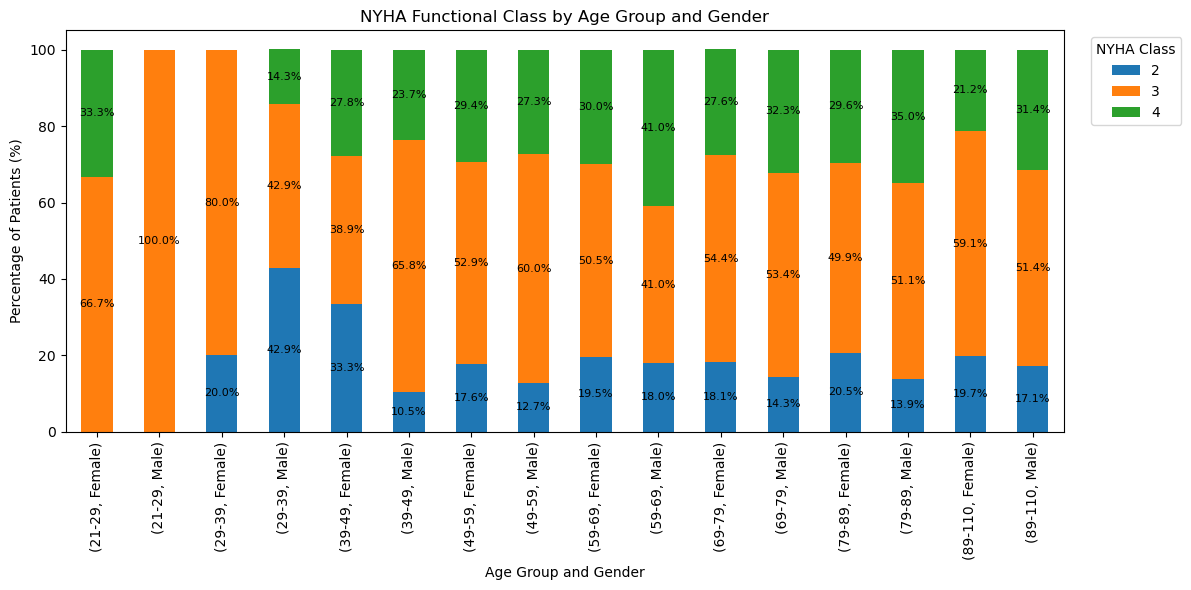

In [141]:
nyha_by_age_gender = pd.crosstab(
    [dfPatientprofile["agecat"], dfPatientprofile["gender"]],
    dfPatientprofile["nyha_cardiac_function_classification"],
    normalize="index"
).mul(100).round(1)

nyha_by_age_gender

# Plot
ax = nyha_by_age_gender.plot(kind="bar",stacked=True, figsize=(12, 6))


plt.title("NYHA Functional Class by Age Group and Gender")
plt.xlabel("Age Group and Gender")
plt.ylabel("Percentage of Patients (%)")
plt.legend(title="NYHA Class", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=90)

# Add percentage labels
for container in ax.containers:
    labels = [
        f"{bar.get_height():.1f}%" if bar.get_height() >= 5 else ""
        for bar in container
    ]
    ax.bar_label(
        container,
        labels=labels,
        label_type="center",
        fontsize=8
    )
plt.tight_layout()
plt.show()

#### NYHA Class 3 is the most common category across most age and gender groups, while Class 4 generally represents a smaller proportion; among older patients, males tend to have a higher proportion of Class 4 than females.

### Question 3: What major cardiovascular conditions and comorbidities are commonly present among heart-attack patients?
#### This analysis summarizes the prevalence of major cardiovascular conditions and comorbidities among heart-attack patients.

In [142]:
# Major cardiovascular conditions and comorbidities
history_cols = ["congestive_heart_failure","peripheral_vascular_disease","cerebrovascular_disease",
    "diabetes", "moderate_to_severe_chronic_kidney_disease", "chronic_obstructive_pulmonary_disease", "liver_disease"]

# Calculate percentage of patients with each condition
comorbidity_pct = (dfPatientprofile[history_cols].mean().mul(100).round(1).sort_values(ascending=False))

# Display results
comorbidity_pct.to_frame("Percentage (%)")

,Percentage (%)
congestive_heart_failure,93.2
moderate_to_severe_chronic_kidney_disease,23.6
diabetes,23.2
chronic_obstructive_pulmonary_disease,11.6
cerebrovascular_disease,7.5
peripheral_vascular_disease,5.0
liver_disease,4.2


### Question 4: What are the death and readmission rates among heart-attack patients within 28 days, 3 months, and 6 months?
#### This analysis shows the percentage of heart-attack patients who died or were readmitted within 28 days, 3 months, and 6 months after admission.

In [143]:
# re_admit variables
re_admit_cols = ["death_within_28_days", "re_admission_within_28_days","death_within_3_months",
    "re_admission_within_3_months", "death_within_6_months","re_admission_within_6_months"]

# Calculate percentage of patients for each outcome
re_admit_pct = (
    dfPatientprofile[re_admit_cols] .mean().mul(100).round(1))

# Display results
re_admit_pct.to_frame("Percentage (%)")

,Percentage (%)
death_within_28_days,1.8
re_admission_within_28_days,7.0
death_within_3_months,2.1
re_admission_within_3_months,24.8
death_within_6_months,2.8
re_admission_within_6_months,38.5


#### Readmission increased from 7.0% within 28 days to 24.8% at 3 months and 38.5% at 6 months, while recorded death rates remained relatively low, increasing from 1.8% to 2.8% over the same periods.

#### Question 5: What is the distribution of different types of heart failure among hospitalized patients?

In [144]:
#calculate patients counts
hf_type_counts = dfPatientprofile["type_of_heart_failure"].value_counts()

# calculate percentage
hf_type_percentage = (
dfPatientprofile["type_of_heart_failure"]
.value_counts(normalize=True)
.mul(100)
.round(2)
)
#print(hf_type_percentage)

# Display the distribution 
hf_type_summary = pd.DataFrame({
"Patient Count": hf_type_counts,
"Percentage": hf_type_percentage
})
hf_type_summary

,Patient Count,Percentage
type_of_heart_failure,,
Both,1480,73.71
Left,477,23.75
Right,51,2.54


#### Question 6: How does left ventricular ejection fraction (LVEF) vary across different types of heart failure?

<Figure size 800x500 with 0 Axes>

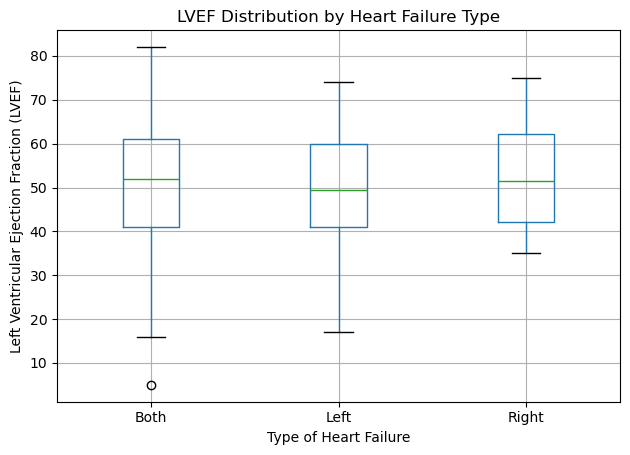

,Patient_Count,Mean_LVEF,Median_LVEF,Minimum_LVEF,Maximum_LVEF
type_of_heart_failure,,,,,
Both,489,50.95,52.0,5.0,82.0
Left,134,49.49,49.5,17.0,74.0
Right,12,53.25,51.5,35.0,75.0


In [145]:
dfPatientprofile["lvef"].isnull().sum()

lvef_summary = (dfPatientprofile.groupby("type_of_heart_failure")["lvef"].agg(
                Patient_Count="count",
                Mean_LVEF="mean",
                Median_LVEF="median",
                Minimum_LVEF="min",
                Maximum_LVEF="max"
                ).round(2))

plt.figure(figsize=(8, 5))
dfPatientprofile.boxplot(
column="lvef",
by="type_of_heart_failure"
)
plt.title("LVEF Distribution by Heart Failure Type")
plt.suptitle("")
plt.xlabel("Type of Heart Failure")
plt.ylabel("Left Ventricular Ejection Fraction (LVEF)")
plt.tight_layout()
plt.show()

lvef_summary

#### Question 7: How is BMI distributed across different age groups among hospitalized heart-failure patients?

Why this question?
Age group (agecat) tells us how patients are distributed by age.
BMI (bmi) describes the patient's body-mass profile.
Comparing BMI across age groups helps us understand the demographic characteristics of the hospitalized heart-failure population.

In [146]:
#Check the two columns
print("Age Group column exists:", "agecat" in dfPatientprofile.columns)
print("BMI column exists:", "bmi" in dfPatientprofile.columns)

# check the missing value
print("Missing Age Group values:", dfPatientprofile["agecat"].isna().sum())
print("Missing BMI values:", dfPatientprofile["bmi"].isna().sum())

Age Group column exists: True
BMI column exists: True
Missing Age Group values: 0
Missing BMI values: 0


<Figure size 1000x600 with 0 Axes>

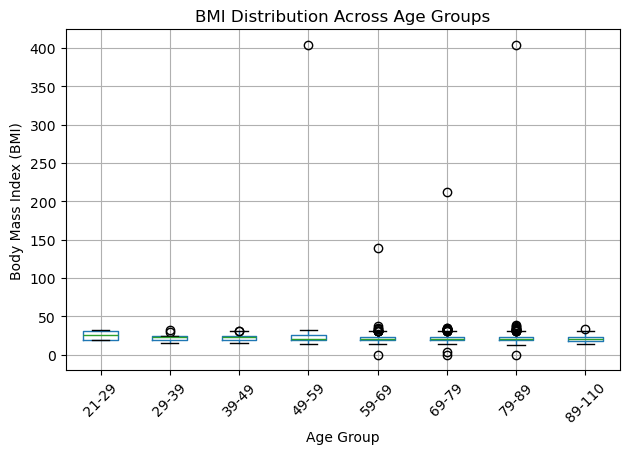

,Patient_Count,Mean_BMI,Median_BMI,Minimum_BMI,Maximum_BMI
agecat,,,,,
21-29,4,24.92,24.81,18.63,31.44
29-39,12,22.41,22.31,14.57,32.46
39-49,56,22.17,22.31,15.31,31.25
49-59,106,25.39,20.81,13.97,404.08
59-69,368,21.74,20.83,0.00,138.89
69-79,715,21.45,20.78,0.00,212.67
79-89,646,21.70,20.55,0.00,404.08
89-110,101,20.85,20.00,14.17,33.29


In [147]:

#Descriptive Statistics
bmi_summary = (
    dfPatientprofile.groupby("agecat")["bmi"]
    .agg(
        Patient_Count="count",
        Mean_BMI="mean",
        Median_BMI="median",
        Minimum_BMI="min",
        Maximum_BMI="max"
    )
    .round(2)
)

#Create Visulalization
plt.figure(figsize=(10, 6))

dfPatientprofile.boxplot(
    column="bmi",
    by="agecat"
)

plt.title("BMI Distribution Across Age Groups")
plt.suptitle("")
plt.xlabel("Age Group")
plt.ylabel("Body Mass Index (BMI)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()
bmi_summary

#### Question 8: Which medications are most frequently prescribed among hospitalized heart-failure patients?
#Why this question?

The prescription dataset contains: 
- inpatient_number → patient identifier
- drug_name → medication prescribed

This allows us to understand medication utilization patterns among hospitalized heart-failure patients.

In [148]:
print("Prescription data loaded successfully!")
print("Rows:", dfPrescriptions.shape[0])
print("Columns:", dfPrescriptions.shape[1])

#check the columns
print(dfPrescriptions.columns.tolist())

Prescription data loaded successfully!
Rows: 15362
Columns: 2
['inpatient_number', 'drug_name']


In [149]:
#Count how frequently each medication was prescribed
drug_counts = dfPrescriptions["drug_name"].value_counts()

drug_percentage = (
    dfPrescriptions["drug_name"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

drug_summary = pd.DataFrame({
    "Prescription_Count": drug_counts,
    "Percentage": drug_percentage
})

drug_summary

,Prescription_Count,Percentage
drug_name,,
Spironolactone tablet,1833,11.93
Furosemide injection,1718,11.18
Furosemide tablet,1641,10.68
Meglumine Adenosine Cyclophosphate for injection,1114,7.25
Deslanoside injection,1015,6.61
Digoxin tablet,998,6.50
Aspirin enteric-coated tablet,958,6.24
Atorvastatin calcium tablet,822,5.35
Milrinone injection,707,4.60


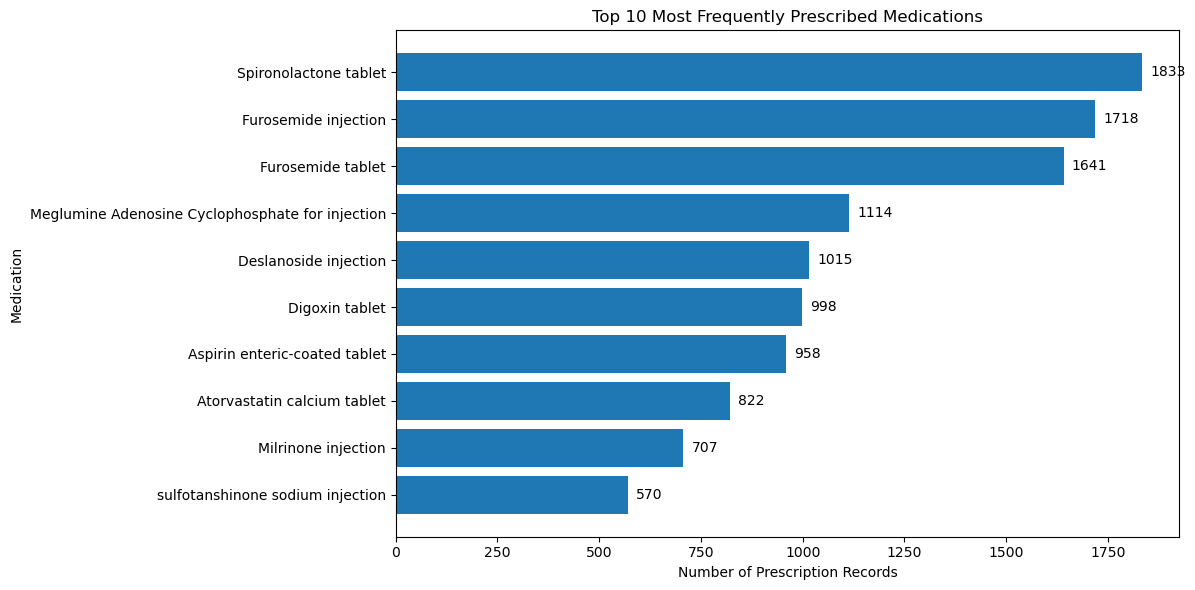

In [150]:
#Create medication chart for top 10 medications prescribed

#Get top 10
top_10_drugs = drug_summary.head(10)

plt.figure(figsize=(12, 6))

bars = plt.barh(
    top_10_drugs.index[::-1],
    top_10_drugs["Prescription_Count"][::-1]
)

plt.title("Top 10 Most Frequently Prescribed Medications")
plt.xlabel("Number of Prescription Records")
plt.ylabel("Medication")

for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 20,
        bar.get_y() + bar.get_height() / 2,
        f"{int(width)}",
        va="center"
    )

plt.tight_layout()
plt.show()

#### Insights : The analysis identifies the medications most frequently recorded in the prescription dataset. The top medications can be 
compared based on their prescription counts, allowing us to understand the medication utilization pattern among hospitalized 
heart-failure patients.

#### Question 9 : Distribution of Hemoglobin in patients based on Diebetes status 

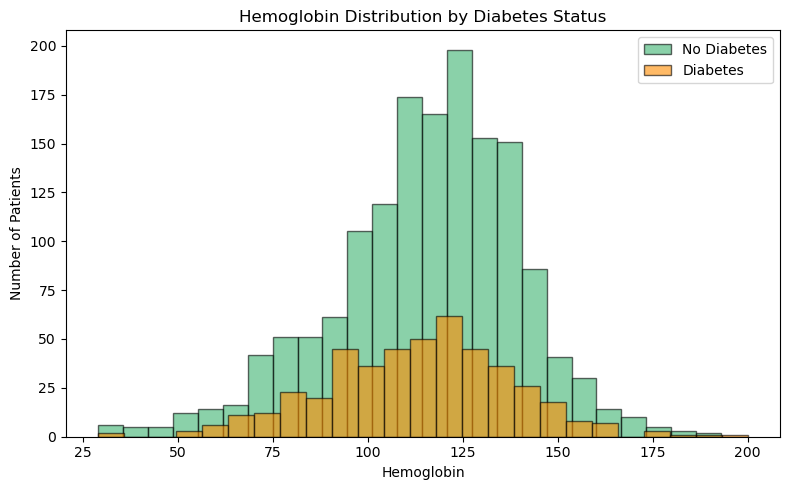

In [151]:
# Overlay two histograms (diabetic vs. non-diabetic) to visually compare
# the shape and spread of hemoglobin values between the two groups
plt.figure(figsize=(8, 5))
plt.hist(dfPatientprofile.loc[dfPatientprofile['diabetes'] == 0, 'hemoglobin'].dropna(), bins=25, alpha=0.6,
         label='No Diabetes', color='mediumseagreen', edgecolor='black')
plt.hist(dfPatientprofile.loc[dfPatientprofile['diabetes'] == 1, 'hemoglobin'].dropna(), bins=25, alpha=0.6,
         label='Diabetes', color='darkorange', edgecolor='black')
plt.title('Hemoglobin Distribution by Diabetes Status')
plt.xlabel('Hemoglobin')
plt.ylabel('Number of Patients')
plt.legend()
plt.tight_layout()
plt.show()

#### Insights : Both groups show a similar, roughly normal hemoglobin distribution centered around 100–125, indicating diabetes status has little visible effect on hemoglobin levels in this cohort.

#### Question 10 : how these two renal markers relate to one another

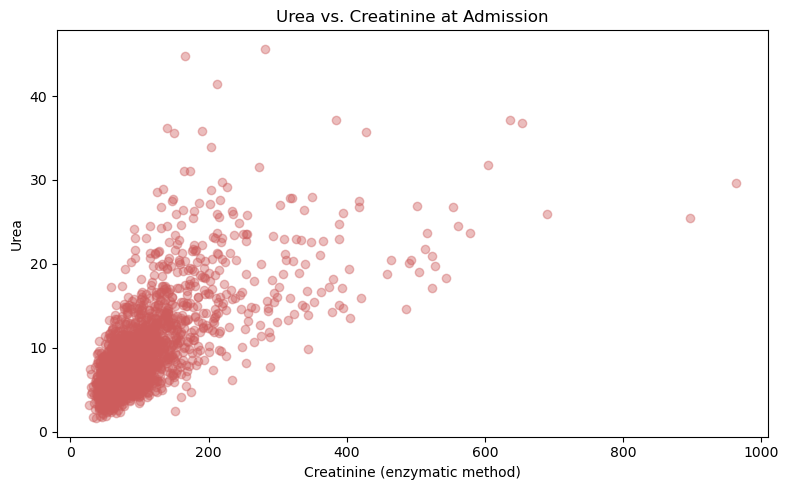

In [152]:
# Plot creatinine vs. urea as a scatter plot to visually inspect
# how these two renal markers relate to one another (alpha reduces overplotting)
plt.figure(figsize=(8, 5))
plt.scatter(dfPatientprofile['creatinine_enzymatic_method'], dfPatientprofile['urea'], alpha=0.4, color='indianred')
plt.title('Urea vs. Creatinine at Admission')
plt.xlabel('Creatinine (enzymatic method)')
plt.ylabel('Urea')
plt.tight_layout()
plt.show()

#### Insights : Urea and creatinine rise together, confirming they both track declining kidney function, with most patients clustered in the normal-to-mildly-impaired range and a smaller group showing severe renal impairment.

-----
# End of Desriptive Analysis